# Traffic assignment and tolls with Gurobi

We will check the traffic assignment of the example projects in `ae-projects/` with Gurobi, checks the result against AequilibraE's own solver, and then try the toll pricing methods of Hearn and Ramana (1998), Section 1.3.

Run `explore_ae_projects.ipynb` first. It saves the AequilibraE assignments `ae_ue`, `ae_so` and `ae_tolled` in each project's results database, and this notebook only reads them.

**Link cost (BPR):** $t_a(v_a) = t^0_a\left(1 + \alpha_a (v_a / c_a)^{\beta_a}\right)$

**Model and Variables (link-node formulation, one commodity per origin):**
- $x^o_a \ge 0$ is the flow on link $a$ that comes from origin $o$.
- $v_a = \sum_o x^o_a$ is the total flow on link $a$.
- Flow conservation: at every node, the flow of origin $o$ that leaves minus the flow that enters equals the trips $o$ sends out (at $o$ itself) or minus the trips it sends to that node.
- User equilibrium (Beckmann): $\min \sum_a \int_0^{v_a} t_a(s)\,ds = \sum_a t^0_a\left(v_a + \frac{\alpha_a c_a}{\beta_a+1}(v_a/c_a)^{\beta_a+1}\right)$
- System optimum: $\min \sum_a v_a\, t_a(v_a) = \sum_a t^0_a\left(v_a + \alpha_a c_a (v_a/c_a)^{\beta_a+1}\right)$

Both objectives are a linear term in $v_a$ plus a multiple of $z_a = (v_a/c_a)^{\beta_a+1}$. With $z_a$ as an extra variable tied to $v_a$ by one power constraint per link, the objective is linear in $(v, z)$.

For the comparison, AequilibraE solves the SO as a UE with marginal costs $t_a + v_a t'_a = t^0_a(1 + \alpha_a(\beta_a+1)(v_a/c_a)^{\beta_a})$, which is BPR with $\alpha' = \alpha(\beta+1)$. $\alpha = 0.15,\ \beta = 4$ for Sioux Falls.

In [1]:
from pathlib import Path

import gurobipy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aequilibrae import Project

AE_DIR = Path("../ae-projects").resolve()
QUIET = gp.Env(params={"OutputFlag": 0})  # one silent Gurobi environment for all models

## Load AE project

Both projects use the same field names (`vdf_fftt`, `capacity`, `vdf_alpha`, `vdf_beta`) and the matrix core `volume`.

In [2]:
def load_links(project):
    """Links of the project, indexed by link_id, with their BPR parameters."""
    links = project.network.links.data.set_index("link_id").sort_index()
    return pd.DataFrame({
        "a_node": links.a_node.astype(int),
        "b_node": links.b_node.astype(int),
        "fftt": links.vdf_fftt.astype(float),
        "capacity": links.capacity_ab.astype(float),
        "alpha": links.vdf_alpha.astype(float),
        "beta": links.vdf_beta.astype(float),
    })


def load_demand(project, matrix_name):
    """Positive O-D demand of a project matrix, indexed by (origin, destination)."""
    matrix = project.matrices.get_matrix(matrix_name)
    zones = np.asarray(matrix.index).flatten()
    volume = pd.DataFrame(np.array(matrix.get_matrix("volume")), index=zones, columns=zones)
    matrix.close()
    demand = volume.stack().rename("demand").rename_axis(["origin", "destination"])
    origin, destination = demand.index.get_level_values(0), demand.index.get_level_values(1)
    return demand[(demand > 0) & (origin != destination)]


def link_flows(project, table_name):
    """Link flows of a results table (AequilibraE or Gurobi), indexed by link_id."""
    return project.results.get_results(table_name).set_index("link_id").volume_ab.rename("flow")


def bpr_time(links, flow):
    """BPR travel time of each link."""
    return links.fftt * (1 + links.alpha * (flow / links.capacity) ** links.beta)

## Traffic assignment in Gurobi / AE and check if they match

AE workflow: build the model from the project, take the run parameters from the project's `parameters.yml`, then run it and save the link flows in the results database we will follow the same for gurobi. 
TODO: add the run parameters for gurobi in `parameters.yml` instead of defining it in notebook/scripts.

In [ ]:
def add_origin_flows(model, links, demand):
    """Add the variables x[origin, link] >= 0 and their flow conservation constraints."""
    nodes = sorted(set(links.a_node) | set(links.b_node))
    out_links, in_links = links.groupby("a_node").groups, links.groupby("b_node").groups
    origins = sorted(demand.index.unique("origin"))
    x = model.addVars(origins, links.index, name="x")
    for o in origins:
        trips = demand.xs(o, level="origin")
        for node in nodes:
            net = trips.sum() if node == o else -trips.get(node, 0.0)
            leaving = gp.quicksum(x[o, a] for a in out_links.get(node, []))
            entering = gp.quicksum(x[o, a] for a in in_links.get(node, []))
            model.addConstr(leaving - entering == net, name=f"node[{o},{node}]")
    return x


def setup_gurobi_model(project, matrix_name, objective="UE", tolls=None):
    """Gurobi model of the traffic assignment of a project matrix, in link flows.

    objective is "UE" (Beckmann) or "SO" (total travel time). `tolls` (a Series per link, in time
    units, may be negative) are added to the link cost of the UE. The link flow variables are
    kept as model._flow and the links table as model._links.
    """
    links, demand = load_links(project), load_demand(project, matrix_name)
    model = gp.Model(f"assignment_{objective}", env=QUIET)
    x = add_origin_flows(model, links, demand)
    v = model.addVars(links.index, name="v")
    model.addConstrs((v[a] == x.sum("*", a) for a in links.index), name="link")

    # z = (v / c) ** (beta + 1), only needed where travel time depends on flow
    congested = links.index[links.alpha > 0]
    z = model.addVars(congested, name="z")
    for a in congested:
        model.addGenConstrNL(z[a], (v[a] / links.capacity[a]) ** (links.beta[a] + 1), name=f"power[{a}]")

    cost = links.fftt + (tolls.reindex(links.index).fillna(0.0) if tolls is not None and objective == "UE" else 0.0)
    weight = links.fftt * links.alpha * links.capacity / (links.beta + 1 if objective == "UE" else 1.0)
    model.setObjective(gp.quicksum(cost[a] * v[a] for a in links.index) + gp.quicksum(weight[a] * z[a] for a in congested))
    model._links, model._flow = links, v
    return model

# TODO: load this from params file. 
def set_model_parameters(model, project):
    """Run parameters: the relative gap of the project's parameters.yml and a one minute limit."""
    model.Params.MIPGap = project.parameters["assignment"]["equilibrium"]["rgap"]
    model.Params.TimeLimit = 60


def save_results(project, table_name, data, procedure, report):
    """Save a table indexed by link_id in the results database, replacing an earlier one."""
    if project.results.check_exists(table_name):
        project.results.delete_record(table_name)
    record = project.results.new_record(table_name, procedure=procedure, procedure_report=report, timestamp=str(pd.Timestamp.now()))
    record.set_data(data.rename_axis("link_id"))


def run_model(project, model, table_name):
    """Optimise the model and save link flows and travel times as `table_name`."""
    model.optimize()
    if model.SolCount == 0:
        raise RuntimeError(f"{model.ModelName}: no solution (Gurobi status {model.Status})")
    links = model._links
    flow = pd.Series({a: max(model._flow[a].X, 0.0) for a in links.index})
    data = pd.DataFrame({"volume_ab": flow, "Congested_Time_AB": bpr_time(links, flow)})
    report = {"solver": "gurobi", "objective": model.ObjVal, "seconds": round(model.Runtime, 3), "status": model.Status}
    save_results(project, table_name, data, "traffic assignment", report)

Its a nonlinear model(due to \beta in power in cost function), which Gurobi solves to a proven gap by spatial branch and bound. The functions are convex and both test networks solve in well under a second.

In [4]:
def mscp_tolls(links, flow):
    """Marginal social cost tolls v * t'(v) at the given (system optimal) flows."""
    return links.fftt * links.alpha * links.beta * (flow / links.capacity) ** links.beta


def solve_all(project, matrix_name):
    """UE, SO and the UE tolled with marginal cost tolls, saved as `ue`, `so` and `tolled`."""
    for objective in ("UE", "SO"):
        model = setup_gurobi_model(project, matrix_name, objective)
        set_model_parameters(model, project)
        run_model(project, model, objective.lower())
        print(f"{objective}: {model.NumVars} variables, {model.NumConstrs} linear and {model.NumGenConstrs} power constraints, "
              f"{model.Runtime:.2f} s, objective {model.ObjVal:,.2f}")
    tolls = mscp_tolls(load_links(project), link_flows(project, "so"))
    model = setup_gurobi_model(project, matrix_name, "UE", tolls)
    set_model_parameters(model, project)
    run_model(project, model, "tolled")

In [5]:
def compare(project):
    """Link flows of both solvers side by side, and a summary of objectives and differences."""
    links = load_links(project)
    table = links[["a_node", "b_node"]].copy()
    for name in ("ue", "so", "tolled"):
        table[f"gurobi_{name}"] = link_flows(project, name)
        table[f"ae_{name}"] = link_flows(project, f"ae_{name}")

    def describe(flow):
        z = (flow / links.capacity) ** (links.beta + 1)
        return {
            "Beckmann objective": (links.fftt * (flow + links.alpha * links.capacity / (links.beta + 1) * z)).sum(),
            "Total travel time": (flow * bpr_time(links, flow)).sum(),
        }

    summary = pd.DataFrame({column: describe(table[column]) for column in table.columns[2:]}).T
    summary["max |Gurobi - AE| flow"] = [(table[f"gurobi_{c.split('_')[1]}"] - table[f"ae_{c.split('_')[1]}"]).abs().max() for c in summary.index]
    return table, summary

## Test for Braess

Demand is 4000 from node 1 to node 4. With the 2→3 shortcut, the UE puts everyone on 1→2→3→4, so each trip takes $41 + 0.01 + 41 = 82.01$.

In [6]:
hearn = Project()
hearn.open(str(AE_DIR / "hearn-example"))
solve_all(hearn, "hearn-example_demand")
hearn_table, hearn_summary = compare(hearn)
hearn_summary

UE: 12 variables, 9 linear and 2 power constraints, 0.01 s, objective 168,040.00
SO: 12 variables, 9 linear and 2 power constraints, 0.00 s, objective 263,204.00


,Beckmann objective,Total travel time,max |Gurobi - AE| flow
gurobi_ue,168040.000000,328040.000000,0.000000e+00
ae_ue,168040.000000,328040.000000,0.000000e+00
gurobi_so,214825.992500,263203.995000,1.057288e-11
ae_so,214825.992500,263203.995000,1.057288e-11
gurobi_tolled,214825.992500,263203.995000,5.144286e+00
ae_tolled,214712.910095,263204.127318,5.144286e+00


In [7]:
hearn_table.round(2)

,a_node,b_node,gurobi_ue,ae_ue,gurobi_so,ae_so,gurobi_tolled,ae_tolled
link_id,,,,,,,,
1,1,2,4000.0,4000.0,2199.5,2199.5,2199.5,2202.07
2,1,3,0.0,0.0,1800.5,1800.5,1800.5,1797.93
3,2,4,0.0,0.0,1800.5,1800.5,1800.5,1797.93
4,3,4,4000.0,4000.0,2199.5,2199.5,2199.5,2202.07
5,2,3,4000.0,4000.0,399.0,399.0,399.0,404.14


In [8]:
tt = hearn_summary["Total travel time"]
print(f"Price of anarchy (UE / SO total travel time): {tt['gurobi_ue'] / tt['gurobi_so']:.4f}")

Price of anarchy (UE / SO total travel time): 1.2463


Closing the shortcut (link 5, 2→3) is one bound on the model: its flow variable is fixed to zero. The UE without the shortcut is faster for everyone.

In [9]:
model = setup_gurobi_model(hearn, "hearn-example_demand", "UE")
set_model_parameters(model, hearn)
model._flow[5].UB = 0.0  # close the shortcut
model.optimize()
no_shortcut = pd.Series({a: model._flow[a].X for a in model._links.index})
print("UE total travel time with shortcut:   ", round(tt["gurobi_ue"], 1))
print("UE total travel time without shortcut:", round((no_shortcut * bpr_time(model._links, no_shortcut)).sum(), 1))

UE total travel time with shortcut:    328040.0
UE total travel time without shortcut: 264000.0


## Sioux Falls

There are 76 one-way links, 24 zones and 360,600 trips.

In [10]:
sf = Project()
sf.open(str(AE_DIR / "sioux-falls"))
solve_all(sf, "sioux-falls_demand")
sf_table, sf_summary = compare(sf)
sf_summary.round(1)

UE: 1976 variables, 652 linear and 76 power constraints, 0.30 s, objective 4,231,443.37


SO: 1976 variables, 652 linear and 76 power constraints, 0.48 s, objective 7,194,256.05


,Beckmann objective,Total travel time,max |Gurobi - AE| flow
gurobi_ue,4231443.4,7484498.8,156.2
ae_ue,4231400.0,7474788.8,156.2
gurobi_so,4295669.8,7194256.1,23.8
ae_so,4295773.2,7194307.0,23.8
gurobi_tolled,4295633.1,7196070.9,279.5
ae_tolled,4295961.4,7194449.9,279.5


In [11]:
sf_table.round(1)

,a_node,b_node,gurobi_ue,ae_ue,gurobi_so,ae_so,gurobi_tolled,ae_tolled
link_id,,,,,,,,
1,1,2,4486.7,4490.8,7620.0,7614.7,7630.5,7655.6
2,1,3,8046.6,8117.4,11239.6,11240.8,11159.3,11222.7
3,2,1,4446.6,4517.4,7639.6,7640.8,7559.3,7622.6
4,2,6,5985.3,5963.3,6620.0,6614.7,6630.5,6655.7
5,3,1,8086.7,8090.8,11220.0,11214.7,11230.5,11255.8
...,...,...,...,...,...,...,...,...
72,23,22,9614.2,9621.8,9259.4,9254.2,9439.9,9264.8
73,23,24,7937.0,7894.4,7738.8,7736.0,7607.9,7738.8
74,24,13,11111.7,11105.0,10545.0,10543.6,10423.1,10573.9


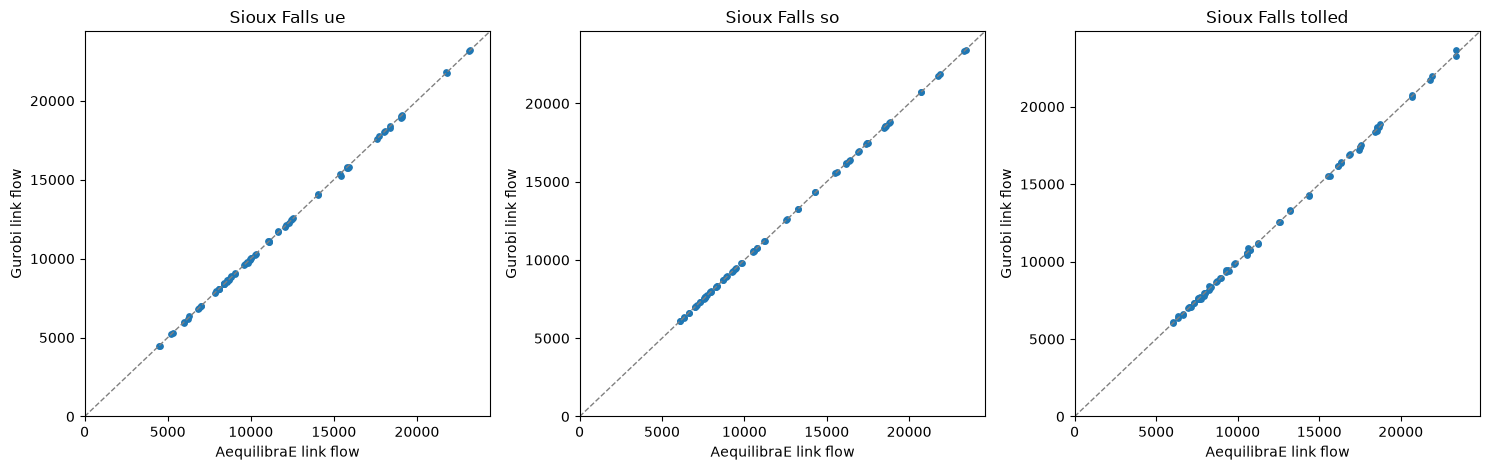

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, kind in zip(axes, ["ue", "so", "tolled"]):
    g, a = sf_table[f"gurobi_{kind}"], sf_table[f"ae_{kind}"]
    ax.scatter(a, g, s=15)
    lim = [0, max(g.max(), a.max()) * 1.05]
    ax.plot(lim, lim, color="grey", lw=1, ls="--")
    ax.set(xlim=lim, ylim=lim, xlabel="AequilibraE link flow", ylabel="Gurobi link flow", title=f"Sioux Falls {kind}")
plt.tight_layout()
plt.show()

In [13]:
tt = sf_summary["Total travel time"]
print(f"Price of anarchy (UE / SO total travel time): {tt['gurobi_ue'] / tt['gurobi_so']:.4f}")
print(f"largest link flow difference to the SO: before tolling {(sf_table.gurobi_ue - sf_table.gurobi_so).abs().max():,.0f}, "
      f"after tolling {(sf_table.gurobi_tolled - sf_table.gurobi_so).abs().max():,.0f}")

Price of anarchy (UE / SO total travel time): 1.0403
largest link flow difference to the SO: before tolling 4,304, after tolling 257


## Toll pricing (Hearn and Ramana)

Marginal cost tolls are one way to make the UE system optimal. The paper describes how to solve for secondary objectives too. For the system optimal flow $v^*$ with link times $s = s(v^*)$, a toll vector $\beta$ is valid when $v^*$ is a UE for the costs $s + \beta$. In the link-node form used here, with $\rho^o_i$ the cost of reaching node $i$ from origin $o$:

$$\rho^o_j - \rho^o_i \le s_a + \beta_a \quad \text{for every origin } o \text{ and link } a = (i, j), \qquad \sum_a (s_a + \beta_a)\, v^*_a = \sum_{o,d} q_{od}\, \rho^o_d .$$

The inequalities say that no route is cheaper than $\rho$. The equality says that the traffic only uses cheapest routes. 

| method | objective | tolls |
|---|---|---|
| MSCP | none, closed form $\beta_a = v_a t_a'(v_a)$ | $\ge 0$ |
| MINSYS | least total toll collected $\beta^T v^*$ | $\ge 0$ |
| MINMAX | least maximum link toll | $\ge 0$ |
| MINTB | fewest tolled links (binary $y_a$, $\beta_a \le M y_a$) | $\ge 0$ |
| RH (Robin Hood) | total toll collected is zero | free |
| MINTB/RH | fewest tolled links, total toll collected is zero | free |

<!-- Notes:
* $v^*$ is only known up to the assignment gap, so the equality is relaxed to "the left side exceeds the right side by at most `rgap` times the total travel time". That is the relative gap of the tolled equilibrium, the same quantity AequilibraE stops on.
* The paper's Robin Hood programme has a constant objective (the total toll is fixed at zero), so the solver may return any point, including absurd ones. Here RH minimises the tolls collected, which equal the subsidies paid, so the least money is moved. No subsidy may exceed the travel time of its link, which keeps every link cost non-negative. The closed form $\beta^{RH} = -s + \lambda(\beta^{MSCP} + s)$ of Section 1.2.4 is shown for comparison. -->

In [14]:
def toll_model(links, demand, flow, method, rgap=1e-4):
    """Gurobi model that picks tolls from the toll set of the system optimal `flow`.

    method is "MINSYS", "MINMAX", "MINTB", "RH" or "MINTB_RH". The toll variables are kept as model._toll.
    """
    time = bpr_time(links, flow)
    subsidies = method in ("RH", "MINTB_RH")
    nodes = sorted(set(links.a_node) | set(links.b_node))
    origins = sorted(demand.index.unique("origin"))

    model = gp.Model(f"tolls_{method}", env=QUIET)
    toll = model.addVars(links.index, lb=-gp.GRB.INFINITY if subsidies else 0.0, name="toll")
    rho = model.addVars(origins, nodes, lb=-gp.GRB.INFINITY, name="rho")

    # Toll set
    model.addConstrs((rho[o, o] == 0 for o in origins), name="origin")
    model.addConstrs((rho[o, links.b_node[a]] - rho[o, links.a_node[a]] <= time[a] + toll[a]
                      for o in origins for a in links.index), name="route")
    revenue = gp.quicksum(flow[a] * toll[a] for a in links.index)
    cheapest = gp.quicksum(trips * rho[o, d] for (o, d), trips in demand.items())
    system_time = float((flow * time).sum())
    model.addConstr(system_time + revenue - cheapest <= rgap * system_time, name="equilibrium")

    # Secondary objective
    if subsidies:
        model.addConstrs((toll[a] >= -time[a] for a in links.index), name="no_negative_cost")
        model.addConstr(revenue == 0, name="revenue_neutral")
    if method == "MINSYS":
        model.setObjective(revenue)
    elif method == "MINMAX":
        largest = model.addVar(name="largest")
        model.addConstrs((largest >= toll[a] for a in links.index), name="largest")
        model.setObjective(largest)
    elif method == "RH":
        collected = model.addVars(links.index, name="collected")
        model.addConstrs((collected[a] >= toll[a] for a in links.index), name="collected")
        model.setObjective(gp.quicksum(flow[a] * collected[a] for a in links.index))
    elif method in ("MINTB", "MINTB_RH"):
        big = float(time.sum())  # exceeds any sensible toll
        booth = model.addVars(links.index, vtype=gp.GRB.BINARY, name="booth")
        model.addConstrs((toll[a] <= big * booth[a] for a in links.index), name="booth_toll")
        if subsidies:
            model.addConstrs((toll[a] >= -big * booth[a] for a in links.index), name="booth_subsidy")
        model.setObjective(booth.sum())
    model._toll = toll
    return model


def explore_tolls(project, matrix_name, methods):
    """Tolls of every method for the saved SO flows of a project, and a summary per method."""
    links, demand, flow = load_links(project), load_demand(project, matrix_name), link_flows(project, "so")
    rgap = project.parameters["assignment"]["equilibrium"]["rgap"]
    time = bpr_time(links, flow)
    tolls = pd.DataFrame({"SO flow": flow, "SO time": time, "MSCP": mscp_tolls(links, flow)})
    status = {"MSCP": "closed form"}
    for method in methods:
        model = toll_model(links, demand, flow, method, rgap)
        model.Params.TimeLimit = 60
        model.optimize()
        tolls[method] = pd.Series({a: model._toll[a].X for a in links.index})
        status[method] = "optimal" if model.Status == gp.GRB.OPTIMAL else f"stopped at 60 s, gap {model.MIPGap:.0%}"
    lam = (time @ flow) / (tolls.MSCP @ flow + time @ flow)
    tolls["RH closed form"] = -time + lam * (tolls.MSCP + time)
    status["RH closed form"] = "closed form"

    methods = tolls.columns[2:]
    tolls[methods] = tolls[methods].where(tolls[methods].abs() > 1e-6, 0.0)
    summary = pd.DataFrame({
        "total tolls": tolls[methods].mul(flow, axis=0).sum(),
        "tolls / total time (%)": 100 * tolls[methods].mul(flow, axis=0).sum() / (time @ flow),
        "toll booths": (tolls[methods] != 0).sum(),
        "largest toll": tolls[methods].max(),
        "largest subsidy": -tolls[methods].min().clip(upper=0),
    })
    # Check: the UE with these tolls should be the SO again
    for method in methods:
        model = setup_gurobi_model(project, matrix_name, "UE", tolls[method])
        set_model_parameters(model, project)
        model.optimize()
        tolled = pd.Series({a: model._flow[a].X for a in links.index})
        summary.loc[method, "max |tolled UE - SO| flow"] = (tolled - flow).abs().max()
    summary["solver"] = pd.Series(status)
    return tolls, summary

### Braess network

One O-D pair and three routes. MSCP tolls the two congested links. MINSYS and MINTB find that a single toll booth on the shortcut is enough, and it collects a tenth of the MSCP revenue. Robin Hood tolls the shortcut and pays the users of the two long links.

In [15]:
ALL_METHODS = ["MINSYS", "MINMAX", "MINTB", "RH", "MINTB_RH"]
hearn_tolls, hearn_toll_summary = explore_tolls(hearn, "hearn-example_demand", ALL_METHODS)
hearn_tolls.round(3)

,SO flow,SO time,MSCP,MINSYS,MINMAX,MINTB,RH,MINTB_RH,RH closed form
link_id,,,,,,,,,
1,2199.5,22.995,21.995,0.000,10.994,0.000,0.000,19.794,9.902
2,1800.5,45.000,0.000,0.000,0.000,0.000,-2.201,-2.186,-12.096
3,1800.5,45.000,0.000,0.000,0.000,0.000,-2.186,-21.995,-12.096
4,2199.5,22.995,21.995,0.000,10.994,0.000,0.000,0.000,9.902
5,399.0,0.010,0.000,21.988,10.994,21.988,19.794,0.000,-0.003


In [16]:
hearn_toll_summary.round(2)

,total tolls,tolls / total time (%),toll booths,largest toll,largest subsidy,max |tolled UE - SO| flow,solver
MSCP,96756.00,36.76,2,22.00,-0.00,0.00,closed form
MINSYS,8773.09,3.33,1,21.99,-0.00,1.46,optimal
MINMAX,52748.47,20.04,3,10.99,-0.00,1.46,optimal
MINTB,8773.09,3.33,1,21.99,-0.00,1.46,optimal
RH,0.00,0.00,3,19.79,2.20,1.46,optimal
MINTB_RH,0.00,0.00,3,19.79,21.99,1.46,optimal
RH closed form,0.00,0.00,5,9.90,12.10,0.00,closed form


Every method reproduces the SO flows as a tolled UE (last check column; flows are around 2000, so a difference of 1 or 2 is the assignment gap).

### Sioux Falls

The two toll booth problems are integer programmes with 76 binaries and a weak big-M bound. They do not finish within the one minute limit on this network, so they are left out here. The other methods take a fraction of a second each.

In [17]:
sf_tolls, sf_toll_summary = explore_tolls(sf, "sioux-falls_demand", ["MINSYS", "MINMAX", "RH"])
sf_toll_summary.round(2)

,total tolls,tolls / total time (%),toll booths,largest toll,largest subsidy,max |tolled UE - SO| flow,solver
MSCP,14492931.31,201.45,76,58.05,-0.00,257.06,closed form
MINSYS,1836448.38,25.53,38,9.12,-0.00,268.47,optimal
MINMAX,1872121.07,26.02,43,8.34,-0.00,266.45,optimal
RH,0.00,0.00,36,3.96,4.80,379.82,optimal
RH closed form,-0.00,-0.00,76,7.30,4.01,106.27,closed form


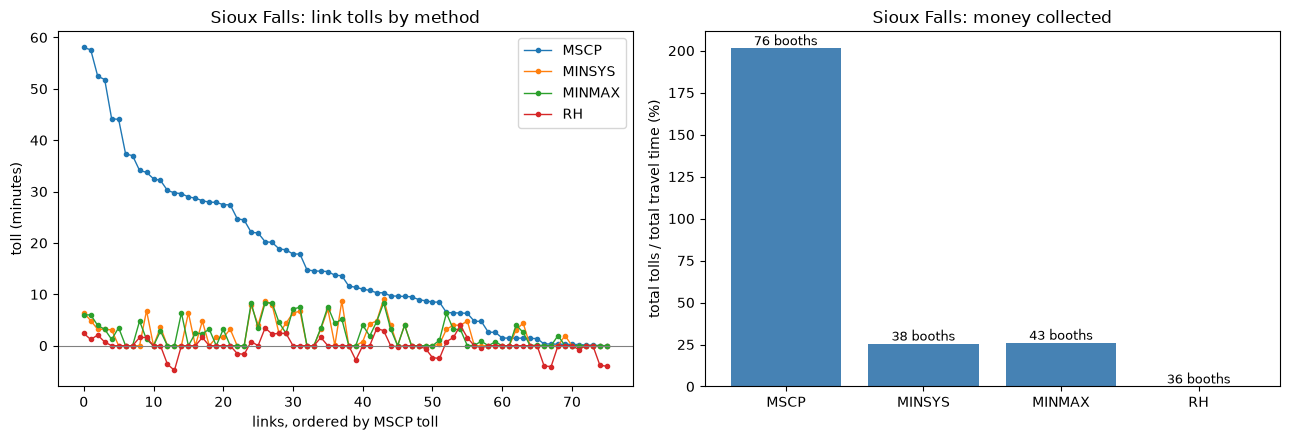

In [18]:
methods = ["MSCP", "MINSYS", "MINMAX", "RH"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ordered = sf_tolls.sort_values("MSCP", ascending=False).reset_index(drop=True)
for method in methods:
    axes[0].plot(ordered.index, ordered[method], marker="o", ms=3, lw=1, label=method)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set(xlabel="links, ordered by MSCP toll", ylabel="toll (minutes)", title="Sioux Falls: link tolls by method")
axes[0].legend()
axes[1].bar(methods, sf_toll_summary.loc[methods, "tolls / total time (%)"], color="steelblue")
axes[1].set(ylabel="total tolls / total travel time (%)", title="Sioux Falls: money collected")
for i, method in enumerate(methods):
    axes[1].annotate(f"{sf_toll_summary.loc[method, 'toll booths']:.0f} booths", (i, sf_toll_summary.loc[method, "tolls / total time (%)"]),
                     ha="center", va="bottom", fontsize=9)
plt.tight_layout()

MSCP tolls every link and collects about twice the total travel time. MINSYS and MINMAX reach the same flows with roughly an eighth of that money and half the booths, and Robin Hood with none at all.

In [19]:
hearn.close()
sf.close()